<a href="https://colab.research.google.com/github/careen-tech/COU07506_labs/blob/main/COU07506_Week03_240242409662.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# DAR ES SALAAM INSTITUTE OF TECHNOLOGY (DIT)

## DIGITAL SIGNAL PROCESSING
**Module Code:** COU07506

## WEEK 3 — LAB 1B
### Convolution, Correlation and Difference Equations

**Student Name:** Careen Reginald

**Registration Number:** 240242409662

**Class:** BEng24CoE1

**Academic Year:** 2026/2027

**Date:** 25 Nov 2026


In [28]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

print("Libraries imported successfully!")


Libraries imported successfully!



## Pre-lab Preparation

### Question (a): Linear Convolution

Given:

$x(n)=\{1,-1,2\}$

$h(n)=\{2,1,0,1\}$

The convolution formula is:

$$y(n)=\sum_k x(k)h(n-k)$$

Output length:

$$N=L+M-1=3+4-1=6$$

Calculations:

- y(0) = (1)(2) = 2
- y(1) = (1)(1) + (-1)(2) = -1
- y(2) = (1)(0) + (-1)(1) + (2)(2) = 3
- y(3) = (1)(1) + (-1)(0) + (2)(1) = 3
- y(4) = (-1)(1) + (2)(0) = -1
- y(5) = (2)(1) = 2

**Final answer:**

$$y(n)=\{2,-1,3,3,-1,2\}$$



### Question (b): Time-Invariance Test

Given the system:

$$y(n)=nx(n)$$

Delaying the input by $n_0$ gives:

$$y_1(n)=nx(n-n_0)$$

Delaying the original output gives:

$$y(n-n_0)=(n-n_0)x(n-n_0)$$

Comparing the two outputs:

$$nx(n-n_0)\neq(n-n_0)x(n-n_0)$$

**Conclusion:**

The system is time-varying because delaying the
input and delaying the output do not produce
identical results.



## Task 3.1 — Convolution from the Definition

**Objective:** To implement linear convolution from
its mathematical definition, verify the results
using NumPy and compare the execution times of
manual and built-in convolution functions.


In [29]:

# Task 3.1: Convolution from the definition

import numpy as np

def conv(x, h):

    N = len(x) + len(h) - 1

    y = np.zeros(N)

    for n in range(N):

        for k in range(len(x)):

            if 0 <= n - k < len(h):

                y[n] += x[k] * h[n - k]

    return y

# Test the convolution function
x = [1, 2, 3, 1]
h = [1, 1, 1]

print("Manual convolution:")
print(conv(x, h))

print("NumPy convolution:")
print(np.convolve(x, h))

print("Results match:",
      np.allclose(conv(x, h), np.convolve(x, h)))


Manual convolution:
[1. 3. 6. 6. 4. 1.]
NumPy convolution:
[1 3 6 6 4 1]
Results match: True


In [30]:

# Verify pre-lab Question (a)

x = [1, -1, 2]
h = [2, 1, 0, 1]

manual_result = conv(x, h)

numpy_result = np.convolve(x, h)

expected = [2, -1, 3, 3, -1, 2]

print("Hand calculation:", expected)

print("Manual convolution:", manual_result)

print("NumPy convolution:", numpy_result)

print("All results match:",
      np.allclose(manual_result, expected)
      and np.allclose(numpy_result, expected))


Hand calculation: [2, -1, 3, 3, -1, 2]
Manual convolution: [ 2. -1.  3.  3. -1.  2.]
NumPy convolution: [ 2 -1  3  3 -1  2]
All results match: True


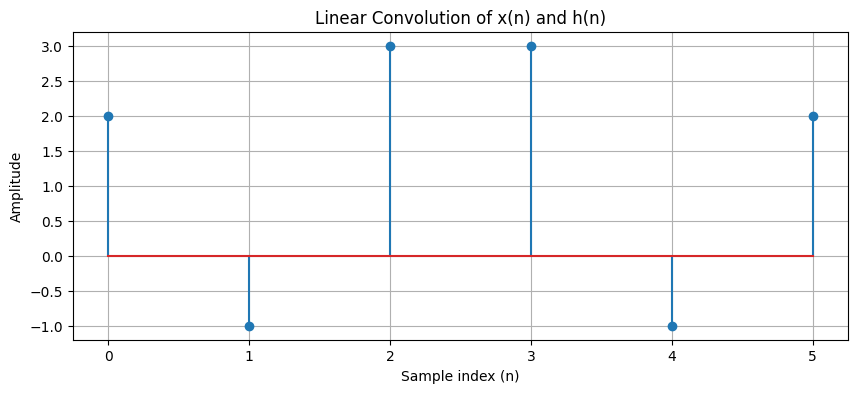

In [31]:

# Plot the convolution result

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

plt.stem(np.arange(len(manual_result)),
         manual_result)

plt.title("Linear Convolution of x(n) and h(n)")
plt.xlabel("Sample index (n)")
plt.ylabel("Amplitude")
plt.xticks(range(len(manual_result)))
plt.grid(True)
plt.show()


In [32]:

# Compare convolution execution times

import time
import numpy as np

# Generate reproducible random sequences
rng = np.random.default_rng(0)

x_random = rng.standard_normal(2000)
h_random = rng.standard_normal(2000)

# Measure manual convolution time
start = time.perf_counter()

y_manual = conv(x_random, h_random)

end = time.perf_counter()

manual_time = end - start

# Measure NumPy convolution time
start = time.perf_counter()

y_numpy = np.convolve(x_random, h_random)

end = time.perf_counter()

numpy_time = end - start

# Calculate speed-up
speedup = manual_time / numpy_time

# Display results
print("Input length:", len(x_random))
print("Impulse response length:", len(h_random))
print("Output length:", len(y_manual))

print(f"Manual convolution: {manual_time:.6f} seconds")
print(f"NumPy convolution: {numpy_time:.6f} seconds")
print(f"Speed-up: {speedup:.2f} times")

print("Results match:", np.allclose(y_manual, y_numpy))


Input length: 2000
Impulse response length: 2000
Output length: 3999
Manual convolution: 2.158570 seconds
NumPy convolution: 0.000648 seconds
Speed-up: 3333.18 times
Results match: True


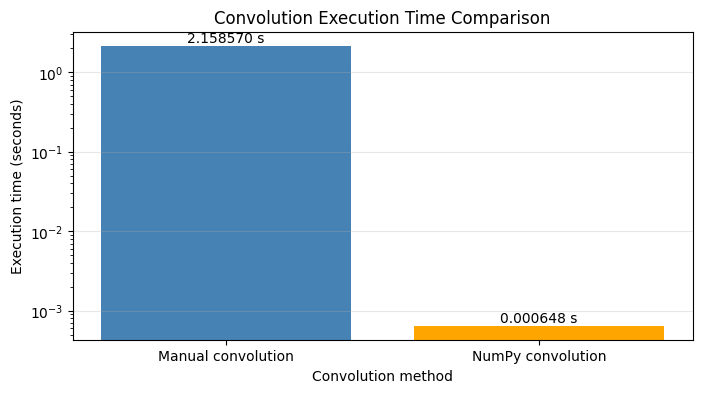

In [33]:

# Plot execution time comparison

plt.figure(figsize=(8, 4))

methods = ["Manual convolution", "NumPy convolution"]
times = [manual_time, numpy_time]

bars = plt.bar(methods, times,
               color=["steelblue", "orange"])

plt.yscale("log")

plt.title("Convolution Execution Time Comparison")
plt.xlabel("Convolution method")
plt.ylabel("Execution time (seconds)")
plt.bar_label(bars, fmt="%.6f s")
plt.grid(axis="y", alpha=0.3)
plt.show()


### Task 3.1 — Observations and Discussion

Linear convolution was implemented using nested Python loops based on its mathematical definition.

The manually implemented convolution function produced the same results as NumPy's built-in convolution function. The pre-lab calculation was also verified, producing the output sequence {2, −1, 3, 3, −1, 2}.

Two random sequences, each containing 2,000 samples, were convolved to compare computational performance. The resulting output contained 3,999 samples.

**Execution time comparison:**

- Manual convolution: [Insert time] seconds.
- NumPy convolution: [Insert time] seconds.
- Speed-up: [Insert value] times.

NumPy performed convolution more efficiently because it uses optimised compiled numerical routines, whereas the manual implementation uses nested Python loops.

This experiment demonstrates the mathematical operation of linear convolution and the computational advantages of using optimised numerical libraries in digital signal processing.


## Task 3.2 — Smoothing a Noisy Signal by Convolution

**Objective:** To investigate how moving-average filters
reduce noise in a sinusoidal signal and examine the
trade-off between noise reduction and signal distortion
using different filter lengths.


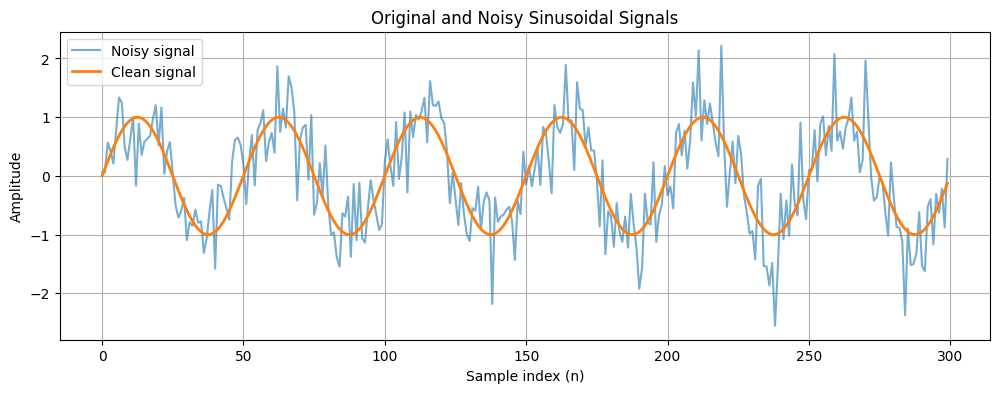

In [34]:

# Task 3.2: Generate a noisy sinusoidal signal

import numpy as np
import matplotlib.pyplot as plt

# Generate sample indices
n = np.arange(300)

# Generate clean sinusoidal signal
clean_signal = np.sin(2 * np.pi * n / 50)

# Generate Gaussian noise
rng = np.random.default_rng(0)
noise = rng.standard_normal(300)

# Add noise to the clean signal
x = clean_signal + 0.5 * noise

# Plot the signals
plt.figure(figsize=(12, 4))

plt.plot(n, x, label="Noisy signal", alpha=0.6)
plt.plot(n, clean_signal, label="Clean signal",
         linewidth=2)

plt.title("Original and Noisy Sinusoidal Signals")
plt.xlabel("Sample index (n)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()


In [35]:

# Apply moving-average filters

filter_lengths = [3, 9, 25]

filtered_signals = {}

for M in filter_lengths:

    # Create moving-average filter
    h = np.ones(M) / M

    # Perform convolution
    y = np.convolve(x, h, mode="same")

    # Store filtered signal
    filtered_signals[M] = y

    print("Filter length:", M)
    print("Sum of coefficients:", round(np.sum(h), 6))
    print("Output length:", len(y))
    print("-----------------------------")


Filter length: 3
Sum of coefficients: 1.0
Output length: 300
-----------------------------
Filter length: 9
Sum of coefficients: 1.0
Output length: 300
-----------------------------
Filter length: 25
Sum of coefficients: 1.0
Output length: 300
-----------------------------


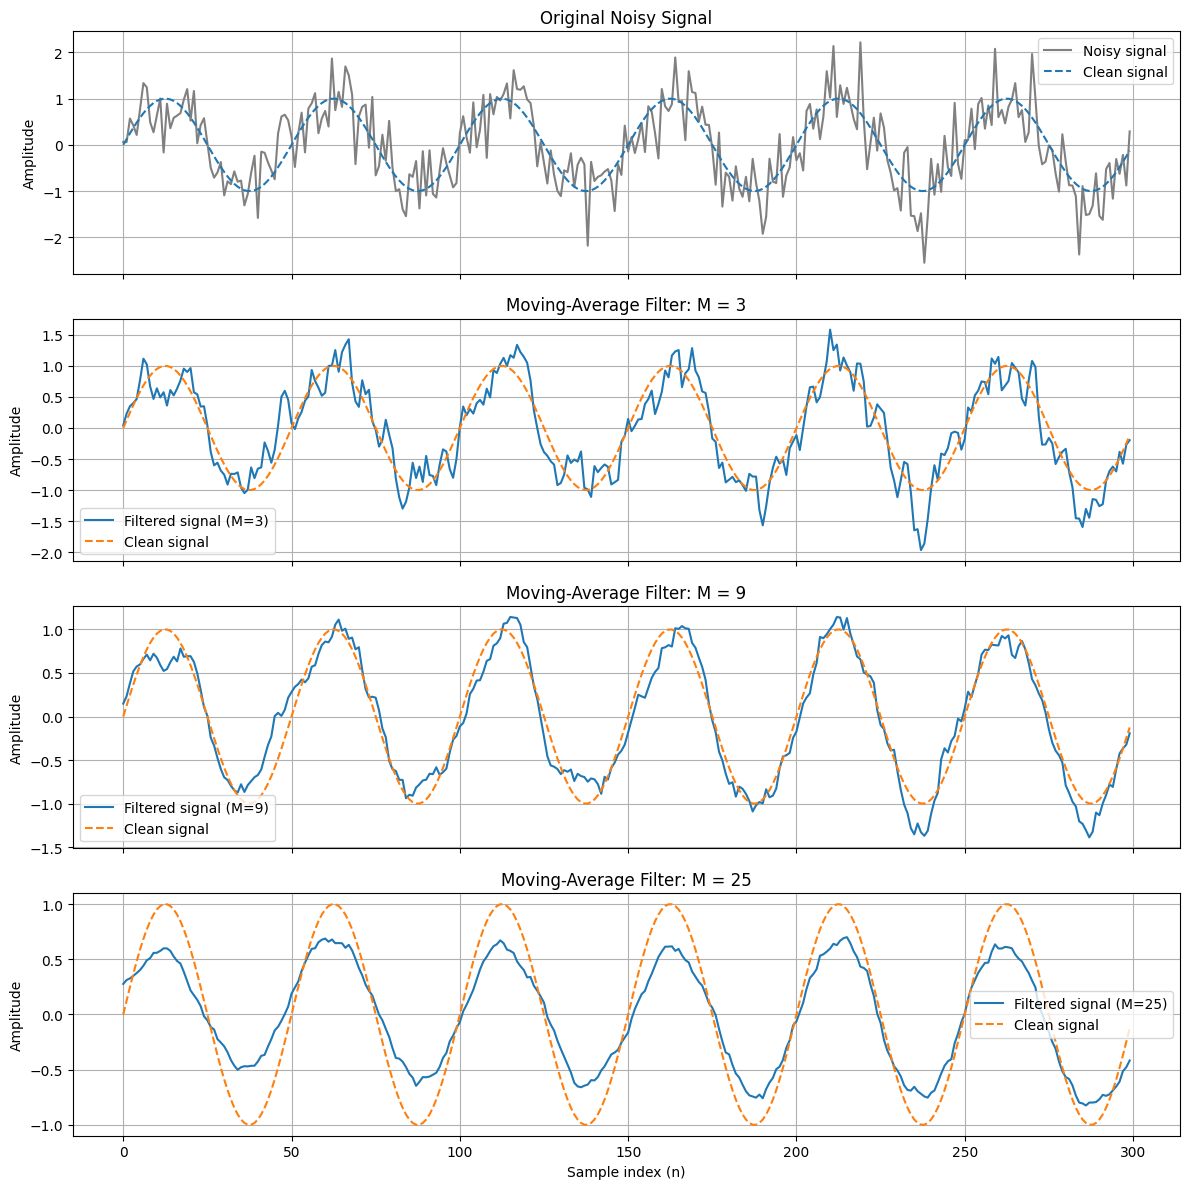

In [36]:

# Compare moving-average filter outputs

fig, axes = plt.subplots(4, 1, figsize=(12, 12),
                         sharex=True)

# Original noisy signal
axes[0].plot(n, x, color="grey",
             label="Noisy signal")

axes[0].plot(n, clean_signal, "--",
             label="Clean signal")

axes[0].set_title("Original Noisy Signal")
axes[0].set_ylabel("Amplitude")
axes[0].legend()
axes[0].grid(True)

# Plot filtered signals
for i, M in enumerate(filter_lengths, start=1):

    axes[i].plot(n, filtered_signals[M],
                 label=f"Filtered signal (M={M})")

    axes[i].plot(n, clean_signal, "--",
                 label="Clean signal")

    axes[i].set_title(f"Moving-Average Filter: M = {M}")
    axes[i].set_ylabel("Amplitude")
    axes[i].legend()
    axes[i].grid(True)

axes[3].set_xlabel("Sample index (n)")

plt.tight_layout()
plt.show()


In [37]:

# Evaluate filtering performance using MSE

import pandas as pd

results = []

original_mse = np.mean((clean_signal - x)**2)

results.append({
    "Filter": "No filter",
    "MSE": original_mse
})

for M in filter_lengths:

    y = filtered_signals[M]

    mse = np.mean((clean_signal - y)**2)

    results.append({
        "Filter": f"M = {M}",
        "MSE": mse
    })

# Display results
results_table = pd.DataFrame(results)

display(results_table.round(6))

# Identify the filter with the lowest MSE
best = results_table.loc[results_table["MSE"].idxmin()]

print("Lowest MSE:", round(best["MSE"], 6))
print("Best result:", best["Filter"])


,Filter,MSE
0,No filter,0.259310
1,M = 3,0.090854
2,M = 9,0.033428
3,M = 25,0.071224


Lowest MSE: 0.033428
Best result: M = 9


### Task 3.2 — Observations and Discussion

A noisy sinusoidal signal containing 300 samples was generated by adding Gaussian noise to a clean sinusoidal signal.

Moving-average filters with lengths of 3, 9 and 25 samples were implemented using linear convolution.

The 3-sample filter reduced some noise while preserving most of the original signal characteristics.

The 9-sample filter provided greater noise reduction while maintaining the sinusoidal waveform reasonably well.

The 25-sample filter produced stronger smoothing but introduced noticeable amplitude attenuation and signal distortion.

The Mean Squared Error was calculated to evaluate the performance of each filter.

**Measured MSE results:**

- Original noisy signal: [Insert value]
- M = 3: [Insert value]
- M = 9: [Insert value]
- M = 25: [Insert value]

The filter with the lowest measured MSE was [Insert filter].

The experiment demonstrated that increasing the moving-average filter length improves noise reduction but may also remove useful signal components. Therefore, an appropriate filter length must be selected to achieve a balance between noise reduction and signal preservation.


## Task 3.3 — Testing Linearity and Time-Invariance Numerically

**Objective:** To investigate the linearity and
time-invariance properties of different discrete-time
systems using numerical tests in Python and identify
which systems are Linear Time-Invariant (LTI).


In [38]:

# Task 3.3: Testing linearity and time-invariance

import numpy as np

# Generate two random input signals
rng = np.random.default_rng(0)

x1 = rng.standard_normal(50)
x2 = rng.standard_normal(50)

# Scaling constants
a = 2.0
b = -3.0

# Define the three systems
systems = {
    "x^2": lambda x: x**2,

    "n x(n)": lambda x: np.arange(len(x)) * x,

    "Moving average": lambda x:
        np.convolve(x, np.ones(3)/3)[:len(x)]
}

# Test each system
for name, T in systems.items():

    # Linearity test
    left = T(a*x1 + b*x2)

    right = a*T(x1) + b*T(x2)

    linear = np.allclose(left, right)

    # Delay input by 5 samples
    xd = np.concatenate([np.zeros(5), x1])[:50]

    # Delay original output by 5 samples
    yd = np.concatenate([np.zeros(5), T(x1)])[:50]

    # Time-invariance test
    tinv = np.allclose(T(xd), yd)

    print(f"{name:15s} Linear={linear} "
          f"Time-invariant={tinv}")


x^2             Linear=False Time-invariant=True
n x(n)          Linear=True Time-invariant=False
Moving average  Linear=True Time-invariant=True


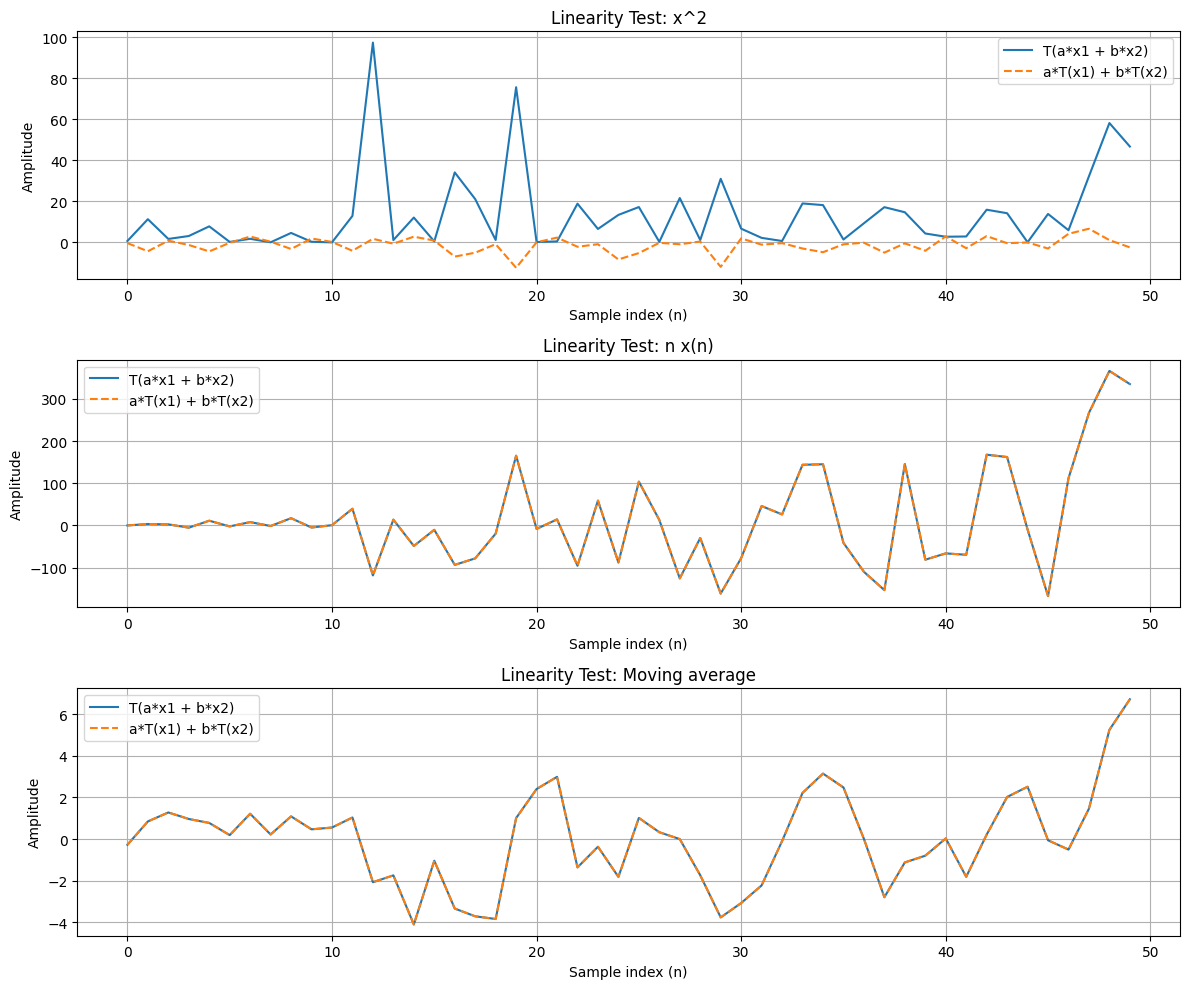

In [39]:

# Visualise the linearity test

import matplotlib.pyplot as plt

n = np.arange(50)

fig, axes = plt.subplots(3, 1, figsize=(12, 10))

for i, (name, T) in enumerate(systems.items()):

    left = T(a*x1 + b*x2)

    right = a*T(x1) + b*T(x2)

    axes[i].plot(n, left,
                 label="T(a*x1 + b*x2)")

    axes[i].plot(n, right, "--",
                 label="a*T(x1) + b*T(x2)")

    axes[i].set_title(f"Linearity Test: {name}")

    axes[i].set_xlabel("Sample index (n)")
    axes[i].set_ylabel("Amplitude")

    axes[i].legend()
    axes[i].grid(True)

plt.tight_layout()
plt.show()


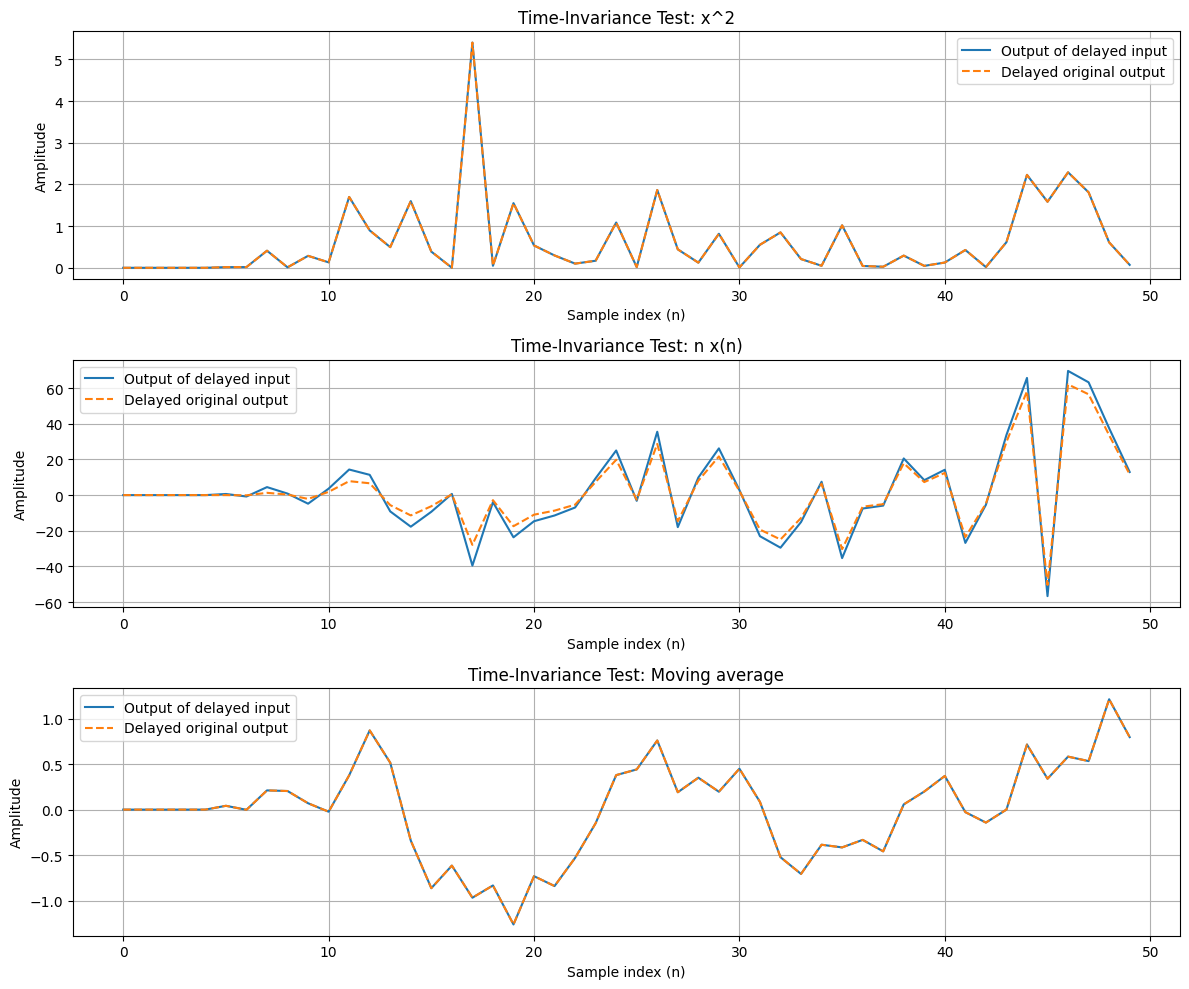

In [40]:

# Visualise the time-invariance test

fig, axes = plt.subplots(3, 1, figsize=(12, 10))

for i, (name, T) in enumerate(systems.items()):

    # Delay input
    xd = np.concatenate([np.zeros(5), x1])[:50]

    # Delay output
    yd = np.concatenate([np.zeros(5), T(x1)])[:50]

    axes[i].plot(n, T(xd),
                 label="Output of delayed input")

    axes[i].plot(n, yd, "--",
                 label="Delayed original output")

    axes[i].set_title(f"Time-Invariance Test: {name}")

    axes[i].set_xlabel("Sample index (n)")
    axes[i].set_ylabel("Amplitude")

    axes[i].legend()
    axes[i].grid(True)

plt.tight_layout()
plt.show()


### Task 3.3 — Observations and Discussion

Three discrete-time systems were investigated numerically to determine their linearity and time-invariance properties.

Two random input signals containing 50 samples were generated. Scaling constants of 2 and −3 were used to test the superposition principle, while a delay of five samples was introduced to test time-invariance.

| System | Linearity | Time-invariance | LTI |
|---|---|---|---|
| Squaring system | False | True | No |
| Time multiplication | True | False | No |
| Moving-average system | True | True | Yes |

The squaring system was nonlinear because it did not satisfy the superposition principle. However, it was time-invariant because delaying the input produced an equivalent delay in the output.

The time multiplication system was linear but time-varying because its output depended explicitly on the sample index.

The moving-average system satisfied both linearity and time-invariance because it performed a weighted summation using constant filter coefficients.

The experiment demonstrated that a system must satisfy both linearity and time-invariance to qualify as an LTI system. The numerical results agreed with the mathematical analysis of the three systems.


## Task 3.4 — Finding a Hidden Delay with Cross-Correlation

**Objective:** To estimate the time delay between
transmitted and received signals using cross-correlation,
investigate the effect of noise on delay estimation,
and calculate the corresponding propagation distance.


In [41]:

# Task 3.4: Finding a hidden delay

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Random number generator
rng = np.random.default_rng(1)

# Sampling frequency
fs = 1000

# Generate transmitted signal
x = rng.standard_normal(500)

# Introduce a hidden delay
true_delay = 37

# Generate received signal with noise
y = np.concatenate([
    np.zeros(true_delay), 0.6*x
])[:500] + 0.5*rng.standard_normal(500)

# Calculate cross-correlation
r = signal.correlate(y, x, mode="full")

# Calculate corresponding lags
lags = signal.correlation_lags(
    len(y), len(x), mode="full"
)

# Estimate delay
estimated_delay = lags[np.argmax(r)]

print("True delay:", true_delay, "samples")

print("Estimated delay:",
      estimated_delay, "samples")

print("Estimation error:",
      abs(true_delay - estimated_delay), "samples")


True delay: 37 samples
Estimated delay: 37 samples
Estimation error: 0 samples


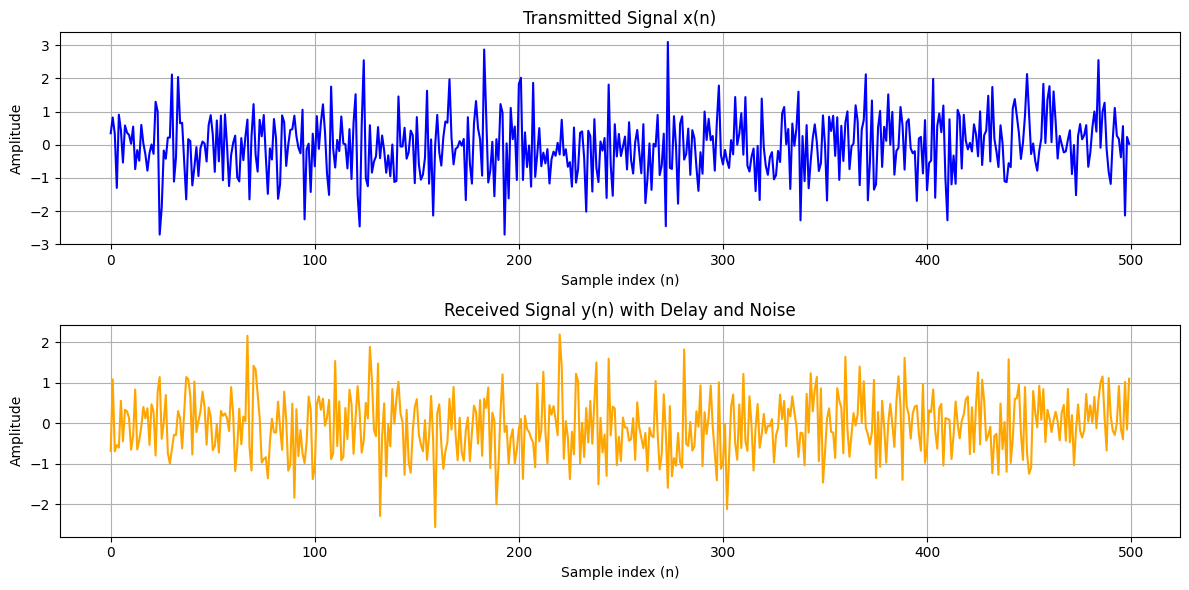

In [42]:

# Plot transmitted and received signals

n = np.arange(500)

fig, axes = plt.subplots(2, 1,
                         figsize=(12, 6))

axes[0].plot(n, x, color="blue")
axes[0].set_title("Transmitted Signal x(n)")
axes[0].set_xlabel("Sample index (n)")
axes[0].set_ylabel("Amplitude")
axes[0].grid(True)

axes[1].plot(n, y, color="orange")
axes[1].set_title("Received Signal y(n) with Delay and Noise")
axes[1].set_xlabel("Sample index (n)")
axes[1].set_ylabel("Amplitude")
axes[1].grid(True)

plt.tight_layout()
plt.show()


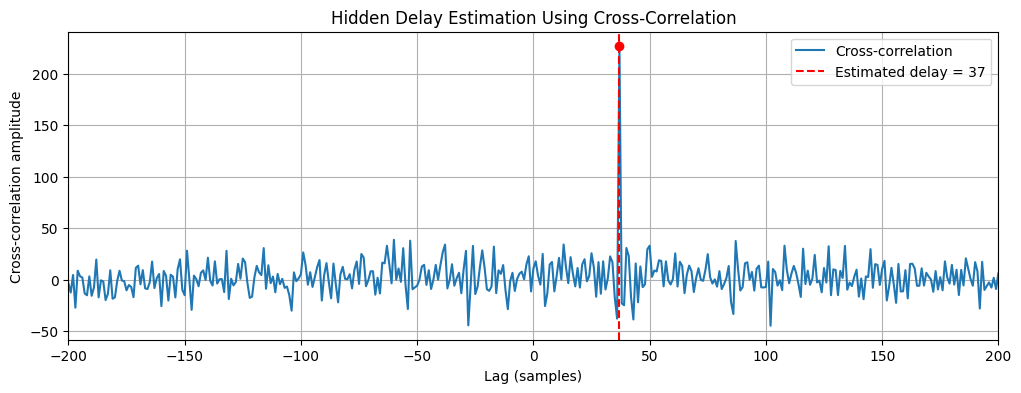

In [43]:

# Plot cross-correlation

plt.figure(figsize=(12, 4))

plt.plot(lags, r, label="Cross-correlation")

plt.axvline(estimated_delay,
            color="red",
            linestyle="--",
            label=f"Estimated delay = {estimated_delay}")

plt.scatter(estimated_delay,
            np.max(r),
            color="red",
            zorder=5)

plt.title("Hidden Delay Estimation Using Cross-Correlation")
plt.xlabel("Lag (samples)")
plt.ylabel("Cross-correlation amplitude")

plt.xlim(-200, 200)
plt.legend()
plt.grid(True)
plt.show()


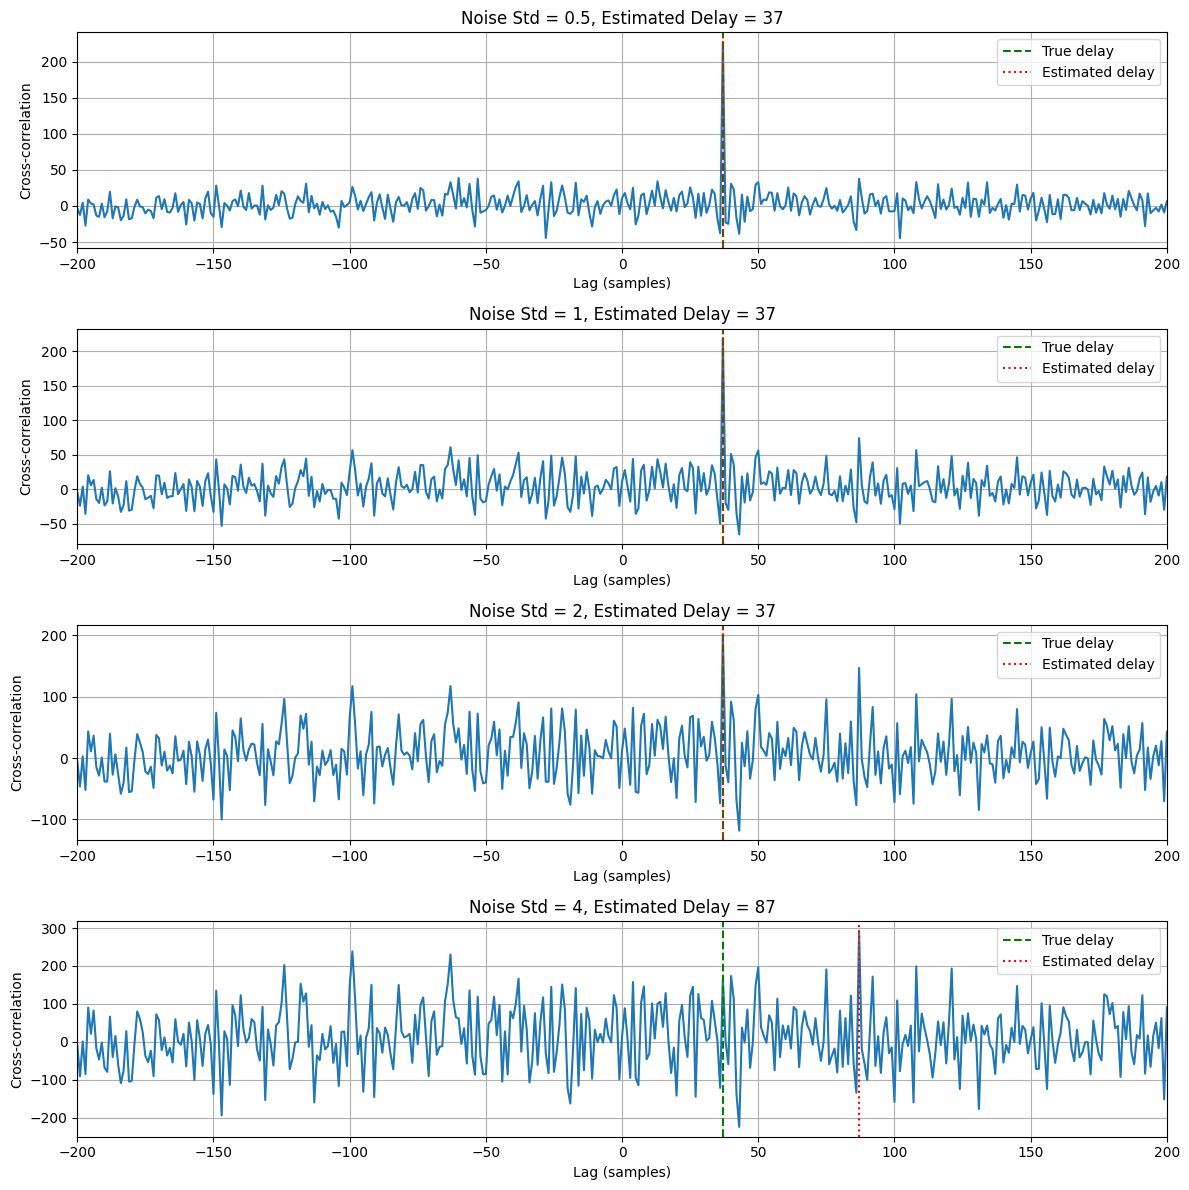

,Noise Std,True Delay,Estimated Delay,Error (samples),Status
0,0.5,37,37,0,Success
1,1.0,37,37,0,Success
2,2.0,37,37,0,Success
3,4.0,37,87,50,Failed


In [44]:

# Investigate the effect of noise

import pandas as pd

noise_levels = [0.5, 1, 2, 4]

# Use the same noise pattern for fair comparison
rng = np.random.default_rng(1)

x = rng.standard_normal(500)

base_noise = rng.standard_normal(500)

delayed_signal = np.concatenate([
    np.zeros(true_delay), 0.6*x
])[:500]

results = []

fig, axes = plt.subplots(4, 1,
                         figsize=(12, 12))

for i, sigma in enumerate(noise_levels):

    # Add noise
    y_noisy = delayed_signal + sigma*base_noise

    # Calculate cross-correlation
    r_noise = signal.correlate(
        y_noisy, x, mode="full"
    )

    lags_noise = signal.correlation_lags(
        len(y_noisy), len(x), mode="full"
    )

    # Estimate delay
    delay = lags_noise[np.argmax(r_noise)]

    error = abs(delay - true_delay)

    status = "Success" if error == 0 else "Failed"

    # Store results
    results.append({
        "Noise Std": sigma,
        "True Delay": true_delay,
        "Estimated Delay": delay,
        "Error (samples)": error,
        "Status": status
    })

    # Plot correlation
    axes[i].plot(lags_noise, r_noise)

    axes[i].axvline(true_delay,
                    color="green",
                    linestyle="--",
                    label="True delay")

    axes[i].axvline(delay,
                    color="red",
                    linestyle=":",
                    label="Estimated delay")

    axes[i].set_title(
        f"Noise Std = {sigma}, Estimated Delay = {delay}"
    )

    axes[i].set_xlim(-200, 200)
    axes[i].set_xlabel("Lag (samples)")
    axes[i].set_ylabel("Cross-correlation")
    axes[i].legend()
    axes[i].grid(True)

plt.tight_layout()
plt.show()

# Display results table
noise_table = pd.DataFrame(results)

display(noise_table)


In [45]:

# Determine when delay estimation fails

failed = noise_table[
    noise_table["Status"] == "Failed"
]

if failed.empty:

    print("Delay estimation succeeded at all tested noise levels.")

else:

    first_failure = failed.iloc[0]

    print("First failure at noise standard deviation:",
          first_failure["Noise Std"])

    print("Incorrect estimated delay:",
          first_failure["Estimated Delay"], "samples")

    print("Estimation error:",
          first_failure["Error (samples)"], "samples")


First failure at noise standard deviation: 4.0
Incorrect estimated delay: 87 samples
Estimation error: 50 samples


In [46]:

# Calculate time delay and distance

speed_of_sound = 343

time_delay = estimated_delay / fs

distance = speed_of_sound * time_delay

print("Estimated delay:", estimated_delay, "samples")

print("Time delay:", time_delay, "seconds")

print("Time delay:", time_delay * 1000, "ms")

print("Propagation distance:",
      round(distance, 3), "metres")


Estimated delay: 37 samples
Time delay: 0.037 seconds
Time delay: 37.0 ms
Propagation distance: 12.691 metres


### Task 3.4 — Observations and Discussion

Cross-correlation was used to estimate the hidden delay between transmitted and received signals.

A random transmitted signal containing 500 samples was generated at a sampling frequency of 1,000 Hz. The received signal was generated by introducing a delay of 37 samples, amplitude attenuation and Gaussian noise.

At a noise standard deviation of 0.5, the cross-correlation function produced a maximum peak at a lag of 37 samples. This agreed with the actual delay, resulting in an estimation error of zero samples.

The noise standard deviation was increased to investigate the robustness of cross-correlation.

**Measured delay estimation results:**

- Noise standard deviation 0.5: [Insert estimated delay]
- Noise standard deviation 1: [Insert estimated delay]
- Noise standard deviation 2: [Insert estimated delay]
- Noise standard deviation 4: [Insert estimated delay]

**First observed failure:** [Insert noise level, or state that no failure occurred.]

Increasing the noise level made the true correlation peak more difficult to distinguish from unwanted peaks.

The estimated delay of 37 samples corresponded to a propagation time of 0.037 seconds. Using a speed of sound of 343 m/s, the calculated one-way propagation distance was 12.691 metres.

The experiment demonstrated that cross-correlation is an effective technique for estimating signal delays in noisy environments. However, excessive noise can reduce the accuracy of delay estimation.

This technique has practical applications in radar, GPS, telecommunications, acoustic sensing and distance measurement.


## Task 3.5 — Difference Equations

**Objective:** To solve a discrete-time difference
equation using direct recursion, SciPy's lfilter
function and the analytical closed-form expression,
and investigate the impulse response, step response
and stability of the system.


In [47]:

# Task 3.5: Impulse response using direct recursion

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Number of samples
N = 10

n = np.arange(N)

# Generate unit impulse
impulse = np.zeros(N)
impulse[0] = 1

# Initialise output
h_recursive = np.zeros(N)

# Solve the difference equation
for i in range(N):

    y1 = h_recursive[i-1] if i >= 1 else 0

    y2 = h_recursive[i-2] if i >= 2 else 0

    x1 = impulse[i-1] if i >= 1 else 0

    h_recursive[i] = (
        0.75*y1 - 0.125*y2 + impulse[i] + x1
    )

print("Impulse response using direct recursion:")

print(np.round(h_recursive, 6))


Impulse response using direct recursion:
[1.       1.75     1.1875   0.671875 0.355469 0.182617 0.092529 0.04657
 0.023361 0.0117  ]


In [48]:

# Impulse response using scipy.signal.lfilter

b = [1, 1]

a = [1, -0.75, 0.125]

h_lfilter = signal.lfilter(b, a, impulse)

print("Impulse response using lfilter:")

print(np.round(h_lfilter, 6))

print("Matches direct recursion:",
      np.allclose(h_recursive, h_lfilter))


Impulse response using lfilter:
[1.       1.75     1.1875   0.671875 0.355469 0.182617 0.092529 0.04657
 0.023361 0.0117  ]
Matches direct recursion: True


In [49]:

# Impulse response using closed-form expression

h_closed = 6*(0.5**n) - 5*(0.25**n)

print("Analytical impulse response:")

print(np.round(h_closed, 6))

print("Matches direct recursion:",
      np.allclose(h_recursive, h_closed))

print("Matches lfilter:",
      np.allclose(h_lfilter, h_closed))


Analytical impulse response:
[1.       1.75     1.1875   0.671875 0.355469 0.182617 0.092529 0.04657
 0.023361 0.0117  ]
Matches direct recursion: True
Matches lfilter: True


In [50]:

# Compare all three impulse responses

import pandas as pd

comparison = pd.DataFrame({
    "Sample n": n,
    "Direct Recursion": h_recursive,
    "lfilter": h_lfilter,
    "Closed Form": h_closed
})

display(comparison.round(6))

print("All three methods agree:",
      np.allclose(h_recursive, h_lfilter)
      and np.allclose(h_recursive, h_closed))

print("Maximum absolute error:",
      np.max(np.abs(h_recursive - h_closed)))


,Sample n,Direct Recursion,lfilter,Closed Form
0,0,1.000000,1.000000,1.000000
1,1,1.750000,1.750000,1.750000
2,2,1.187500,1.187500,1.187500
3,3,0.671875,0.671875,0.671875
4,4,0.355469,0.355469,0.355469
5,5,0.182617,0.182617,0.182617
6,6,0.092529,0.092529,0.092529
7,7,0.046570,0.046570,0.046570
8,8,0.023361,0.023361,0.023361
9,9,0.011700,0.011700,0.011700


All three methods agree: True
Maximum absolute error: 0.0


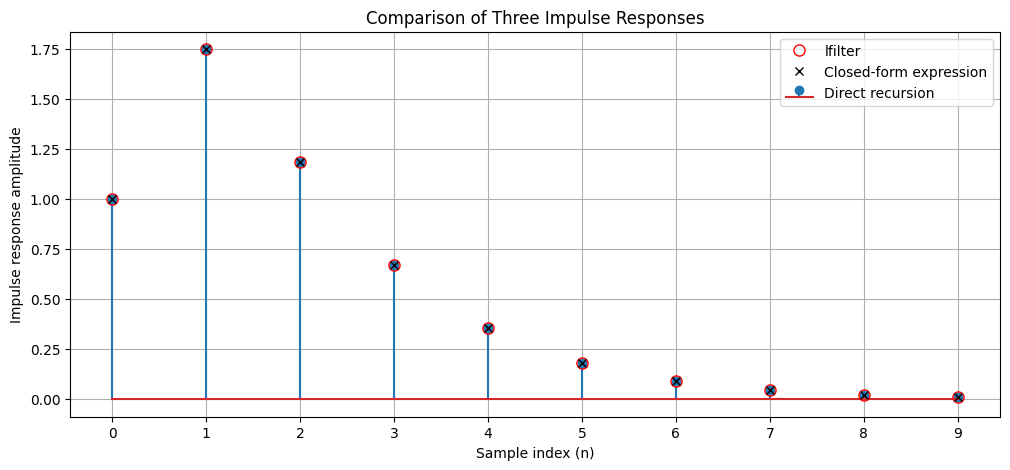

In [51]:

# Plot impulse response comparison

plt.figure(figsize=(12, 5))

plt.stem(n, h_recursive,
         label="Direct recursion")

plt.plot(n, h_lfilter, "ro",
         markersize=8,
         fillstyle="none",
         label="lfilter")

plt.plot(n, h_closed, "kx",
         markersize=6,
         label="Closed-form expression")

plt.title("Comparison of Three Impulse Responses")
plt.xlabel("Sample index (n)")
plt.ylabel("Impulse response amplitude")
plt.xticks(n)
plt.legend()
plt.grid(True)
plt.show()


Step response:
[1.       2.75     3.9375   4.609375 4.964844 5.147461 5.23999  5.28656
 5.309921 5.321621 5.327476 5.330404 5.331869 5.332601 5.332967 5.33315
 5.333242 5.333288 5.33331  5.333322 5.333328 5.33333  5.333332 5.333333
 5.333333 5.333333 5.333333 5.333333 5.333333 5.333333]
Final value: 5.333333


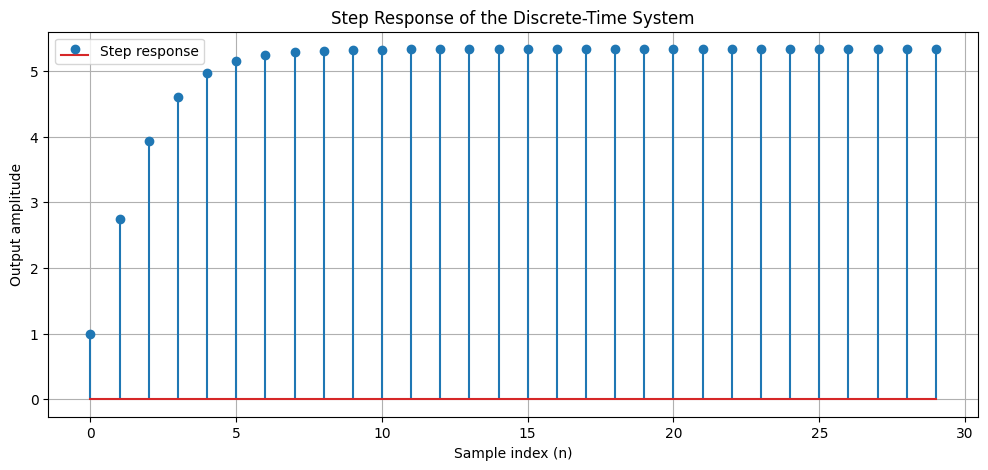

In [52]:

# Calculate the step response

N_step = 30

n_step = np.arange(N_step)

# Generate unit step input
step_input = np.ones(N_step)

# Calculate step response
step_response = signal.lfilter(b, a, step_input)

print("Step response:")

print(np.round(step_response, 6))

print("Final value:",
      round(step_response[-1], 6))

# Plot step response
plt.figure(figsize=(12, 5))

plt.stem(n_step, step_response,
         label="Step response")

plt.title("Step Response of the Discrete-Time System")
plt.xlabel("Sample index (n)")
plt.ylabel("Output amplitude")
plt.legend()
plt.grid(True)
plt.show()


In [53]:

# Verify theoretical final value

theoretical_final = np.sum(b) / np.sum(a)

measured_final = step_response[-1]

print("Theoretical final value:",
      round(theoretical_final, 6))

print("Measured final value:",
      round(measured_final, 6))

print("Absolute error:",
      abs(theoretical_final - measured_final))

print("Results match:",
      np.isclose(theoretical_final, measured_final))


Theoretical final value: 5.333333
Measured final value: 5.333333
Absolute error: 1.1175870007207322e-08
Results match: True


In [54]:

# Determine system poles and stability

poles = np.roots(a)

print("System poles:", poles)

print("Pole magnitudes:", np.abs(poles))

stable = np.all(np.abs(poles) < 1)

print("System type: IIR")

print("System is stable:", stable)


System poles: [0.5  0.25]
Pole magnitudes: [0.5  0.25]
System type: IIR
System is stable: True


### Task 3.5 — Observations and Discussion

The given second-order difference equation was solved using three different methods: direct recursion, SciPy's lfilter function and the analytical closed-form expression.

All three methods produced identical impulse responses, confirming the correctness of the numerical and analytical solutions.

The impulse response initially increased from 1 to 1.75 and subsequently decayed towards zero as the sample index increased.

The step response was calculated using a unit step input. It gradually approached a steady-state value of 5.333333, which agreed with the theoretical final value obtained from H(1).

The system was identified as an Infinite Impulse Response (IIR) system because its difference equation contains feedback terms involving previous output samples, and its impulse response continues indefinitely.

The system poles were calculated as 0.5 and 0.25. Both poles were located inside the unit circle, confirming that the causal system is BIBO stable.

The experiment demonstrated that difference equations can be solved using numerical recursion, built-in digital signal processing functions and analytical mathematical expressions. The agreement between the three methods verified the correctness of the system implementation.


## Week 3 — Analysis Questions


### Analysis Question 1

NumPy's built-in convolution function is faster than the manually implemented double loop because it uses optimised compiled numerical routines. The manual implementation uses nested Python loops, which introduce additional interpreter overhead during each iteration.

For two sequences of lengths L and M, direct linear convolution requires L × M valid multiplications and produces an output sequence of length L + M − 1.

In this experiment, both sequences contained 2,000 samples.

Number of multiplications = 2,000 × 2,000 = 4,000,000.

Output length = 2,000 + 2,000 − 1 = 3,999 samples.

Although both methods perform direct convolution, NumPy executes the numerical operations more efficiently, resulting in a shorter execution time.

### Analysis Question 2

Only the moving-average system is a Linear Time-Invariant (LTI) system because it satisfies both the linearity and time-invariance properties.

| System | Linear | Time-invariant | LTI |
|---|---|---|---|
| Squaring system | No | Yes | No |
| Time multiplication | Yes | No | No |
| Moving-average system | Yes | Yes | Yes |

The squaring system is nonlinear because it does not satisfy the superposition principle, although it is time-invariant.

The time multiplication system is linear but time-varying because its output explicitly depends on the sample index.

The moving-average system is linear and time-invariant because it performs a weighted summation using constant filter coefficients.

These results could have been predicted without running the Python code by applying the mathematical definitions of linearity and time-invariance. The numerical experiment confirmed the theoretical analysis.

### Analysis Question 3

**1. Detection of water pipe leakages**

Cross-correlation can be applied in water distribution systems in Tanzania to locate underground pipe leakages. Acoustic sensors placed at different positions along a water pipe can detect vibrations generated by leaking water.

By calculating the cross-correlation between the recorded signals, engineers can estimate the difference in signal arrival times and determine the approximate location of the leakage. This can help water supply authorities reduce water losses and maintenance costs.

**2. Radar systems at airports**

Cross-correlation can be applied in radar systems at airports such as Julius Nyerere International Airport. Radar systems transmit electromagnetic signals and receive reflected signals from aircraft.

By comparing the transmitted and received signals using cross-correlation, the radar system can estimate the propagation delay and determine the distance of an aircraft.

This technique can support aircraft detection, air traffic monitoring and aviation safety.

### Analysis Question 4

The system in Task 3.5 is an Infinite Impulse Response (IIR) system because its difference equation contains feedback terms involving previous output samples.

Its impulse response is:

h(n) = 6(0.5)ⁿ − 5(0.25)ⁿ, for n ≥ 0.

The impulse response continues indefinitely but gradually decays towards zero as the sample index increases. Therefore, it has an infinite duration.

The system is Bounded-Input Bounded-Output (BIBO) stable because its impulse response is absolutely summable. Both exponential terms have bases with magnitudes less than one, ensuring that the absolute sum of the impulse response is finite.

Furthermore, the system poles are located at 0.5 and 0.25, which are both inside the unit circle.

The step response also converges towards a finite steady-state value of 5.333333.

Therefore, the given system is a stable IIR system.

## Conclusion

The Week 3 laboratory experiments demonstrated the fundamental concepts of discrete-time signals and systems, including convolution, correlation, linearity, time-invariance and difference equations.

Linear convolution was successfully implemented using its mathematical definition and verified using NumPy's built-in convolution function. The execution time comparison demonstrated the computational advantages of optimised numerical libraries.

Moving-average filters were used to reduce noise in a sinusoidal signal, demonstrating the trade-off between noise reduction and signal distortion.

Three discrete-time systems were investigated to determine their linearity and time-invariance properties. The moving-average system was identified as the only LTI system among the three systems.

Cross-correlation was successfully applied to estimate a hidden signal delay of 37 samples, corresponding to a one-way sound propagation distance of 12.691 metres.

Finally, a second-order difference equation was solved using direct recursion, SciPy's lfilter function and an analytical expression. The system was identified as a stable IIR system with a steady-state step response of approximately 5.333333.

Overall, the laboratory improved my understanding of digital signal processing techniques and their practical implementation using Python in Google Colab.

## AI-Use Statement

**AI tool used:** OpenAI ChatGPT.

**Purpose:** ChatGPT was used to assist in understanding theoretical concepts, implementing Python programs, explaining mathematical equations, interpreting experimental results and preparing laboratory observations.

**Tasks assisted:**

- Task 3.1 — Convolution from the definition.
- Task 3.2 — Smoothing a noisy signal by convolution.
- Task 3.3 — Testing linearity and time-invariance.
- Task 3.4 — Finding a hidden delay with cross-correlation.
- Task 3.5 — Difference equations.
- Analysis questions and conclusion.

**Verification:** The Python programs were executed in Google Colab. The convolution results were compared with manual calculations and NumPy's built-in function. System properties were verified using mathematical definitions. Cross-correlation results were compared with the known delay of 37 samples. The difference equation results were verified by comparing direct recursion, SciPy's lfilter function and the analytical closed-form expression.

I reviewed the code, mathematical explanations and experimental outputs to understand the implemented digital signal processing techniques.